# Neft quyularında anomaliyaların aşkarlanması

Bu notebook `src/detector.py` modulundakı addımları bir-bir göstərir: data → təmizləmə → analiz → Isolation Forest → vizuallaşdırma → CSV hesabat.

Data sintetikdir, amma [3W Dataset](https://github.com/petrobras/3W)-dakı hadisə növlərinə (BSW-nin kəskin artması, DHSV-nin özbaşına bağlanması, şiddətli slugging, hidrat) əsaslanır.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image
import detector as d

pd.set_option('display.width', 160)

## 1. Data

3 quyu, 120 gün, saatlıq ölçmələr. `event_type` sütunu yalnız qiymətləndirmə üçündür — model onu görmür.

In [2]:
raw = pd.read_csv('../data/sample_data.csv')
print(raw.shape)
raw.head()

(8665, 8)


,timestamp,well_id,oil_rate_bpd,downhole_pressure_bar,wellhead_pressure_bar,wellhead_temp_c,water_cut_pct,event_type
0,2025-01-06 12:00:00,WELL-B,875.3,189.59,30.58,61.92,40.21,normal
1,2025-01-28 11:00:00,WELL-A,1165.0,213.55,38.20,69.15,22.34,normal
2,2025-04-13 05:00:00,WELL-A,32.4,227.09,14.47,56.74,26.08,dhsv_closure
3,2025-01-25 21:00:00,WELL-B,818.8,189.43,30.92,61.40,41.95,normal
4,2025-01-14 06:00:00,WELL-B,847.0,189.85,31.10,59.40,41.28,normal


In [3]:
raw[d.METRICS].describe().round(1)

,oil_rate_bpd,downhole_pressure_bar,wellhead_pressure_bar,wellhead_temp_c,water_cut_pct
count,8614.0,8614.0,8614.0,8614.0,8614.0
mean,1132.4,209.4,42.3,67.0,27.7
std,280.6,17.3,214.7,5.2,11.8
min,-1.0,182.4,12.1,37.9,12.3
25%,826.5,188.6,31.2,62.0,16.7
50%,1133.6,212.0,37.9,67.7,23.8
75%,1426.4,227.5,43.7,71.3,42.0
max,2067.3,235.0,9999.0,76.2,120.0


Diqqət: `wellhead_pressure_bar` maksimumu 9999, `oil_rate_bpd` minimumu −1, `water_cut_pct` 120 — bunlar sensor xətalarıdır, prosesin özü deyil.

## 2. Təmizləmə

- dublikatlar silinir
- fiziki olaraq mümkün olmayan dəyərlər `NaN` edilir
- ≤3 saatlıq boşluqlar zamana görə interpolyasiya olunur, daha uzunları atılır

In [4]:
df, stats = d.clean_data(raw)
stats

{'rows_in': 8665,
 'duplicates_removed': 25,
 'missing_before': 255,
 'out_of_range_nulled': 12,
 'rows_dropped_long_gaps': 0,
 'rows_out': 8640}

In [5]:
d.describe_metrics(df)

oil_rate_bpd                       downhole_pressure_bar                       wellhead_pressure_bar                     wellhead_temp_c               \
                mean    std    min     max                  mean   std     min     max                  mean   std    min    max            mean   std    min   
well_id                                                                                                                                                         
WELL-A       1132.52  70.44   32.4  1514.5                212.04  2.05  205.99  228.37                 37.89  1.24  14.47  46.73           67.67  1.61  45.13   
WELL-B        801.40  49.56   23.7   877.6                187.05  2.07  182.39  205.85                 31.05  1.49  12.07  52.58           60.64  1.66  37.91   
WELL-C       1466.04  78.91  699.4  2067.3                229.02  1.94  223.29  235.01                 44.02  1.42  34.75  65.02           72.64  1.54  65.87   

               water_cut_pct                      
           max          mean   std    min    max  
well_id                                           
WELL-A   71.36         24.04  2.62  20.43  48.80  
WELL-B   64.43         43.03  2.47  39.51  67.35  
WELL-C   76.24         15.80  1.21  12.26  19.11

## 3. Göstəricilərin analizi

In [6]:
df.groupby('event_type')[d.METRICS].mean().round(1)

,oil_rate_bpd,downhole_pressure_bar,wellhead_pressure_bar,wellhead_temp_c,water_cut_pct
event_type,,,,,
dhsv_closure,194.3,214.2,17.7,52.5,33.1
hydrate_restriction,818.2,209.8,47.6,62.2,29.9
normal,1137.5,209.3,37.6,67.0,27.5
severe_slugging,1306.6,220.9,41.2,70.4,19.5
water_breakthrough,786.8,199.7,34.6,65.7,54.7


Hər hadisənin öz izi var: su keçməsində `water_cut_pct` qalxır, DHSV bağlananda hasilat sıfıra düşür və quyudibi təzyiq artır, hidratda quyuağzı təzyiq yüksəlir, temperatur düşür.

In [7]:
df[d.METRICS].corr().round(2)

,oil_rate_bpd,downhole_pressure_bar,wellhead_pressure_bar,wellhead_temp_c,water_cut_pct
oil_rate_bpd,1.00,0.97,0.95,0.94,-0.95
downhole_pressure_bar,0.97,1.00,0.96,0.94,-0.98
wellhead_pressure_bar,0.95,0.96,1.00,0.92,-0.93
wellhead_temp_c,0.94,0.94,0.92,1.00,-0.93
water_cut_pct,-0.95,-0.98,-0.93,-0.93,1.00


## 4. Isolation Forest

Hər metrik üçün 3 xüsusiyyət: son 7 günün medianından **sapma**, 1 saatlıq **dəyişmə**, 6 saatlıq **volatillik**. Hamısı hər quyu üçün ayrıca robust z-score ilə miqyaslanır.

In [8]:
X = d.build_features(df)
X.describe().T[['mean', 'std', 'min', 'max']].round(2).head(6)

,mean,std,min,max
oil_rate_bpd__level,-0.25,3.21,-62.01,24.63
oil_rate_bpd__diff,0.01,2.18,-47.01,48.15
oil_rate_bpd__vol,0.74,6.31,-2.57,105.02
downhole_pressure_bar__level,0.04,1.31,-6.70,23.76
downhole_pressure_bar__diff,0.00,1.09,-16.20,15.88
downhole_pressure_bar__vol,0.21,2.03,-2.80,38.52


In [9]:
result = d.detect(df, contamination=0.025)
result['is_anomaly'].value_counts()

is_anomaly
False    8424
True      216
Name: count, dtype: int64

In [10]:
d.evaluate(result)

{'precision': np.float64(0.8194444444444444),
 'recall': np.float64(0.8805970149253731),
 'events_detected': '8/8'}

In [11]:
pd.crosstab(result['event_type'], result['is_anomaly'], margins=True)

is_anomaly,False,True,All
event_type,,,
dhsv_closure,2,9,11
hydrate_restriction,12,44,56
normal,8400,39,8439
severe_slugging,3,73,76
water_breakthrough,7,51,58
All,8424,216,8640


## 5. Vizuallaşdırma

Mavi xətt — normal ölçmələr, qırmızı nöqtələr — şübhəli ölçmələr, sarı zolaq — dataya əlavə olunmuş real hadisə.

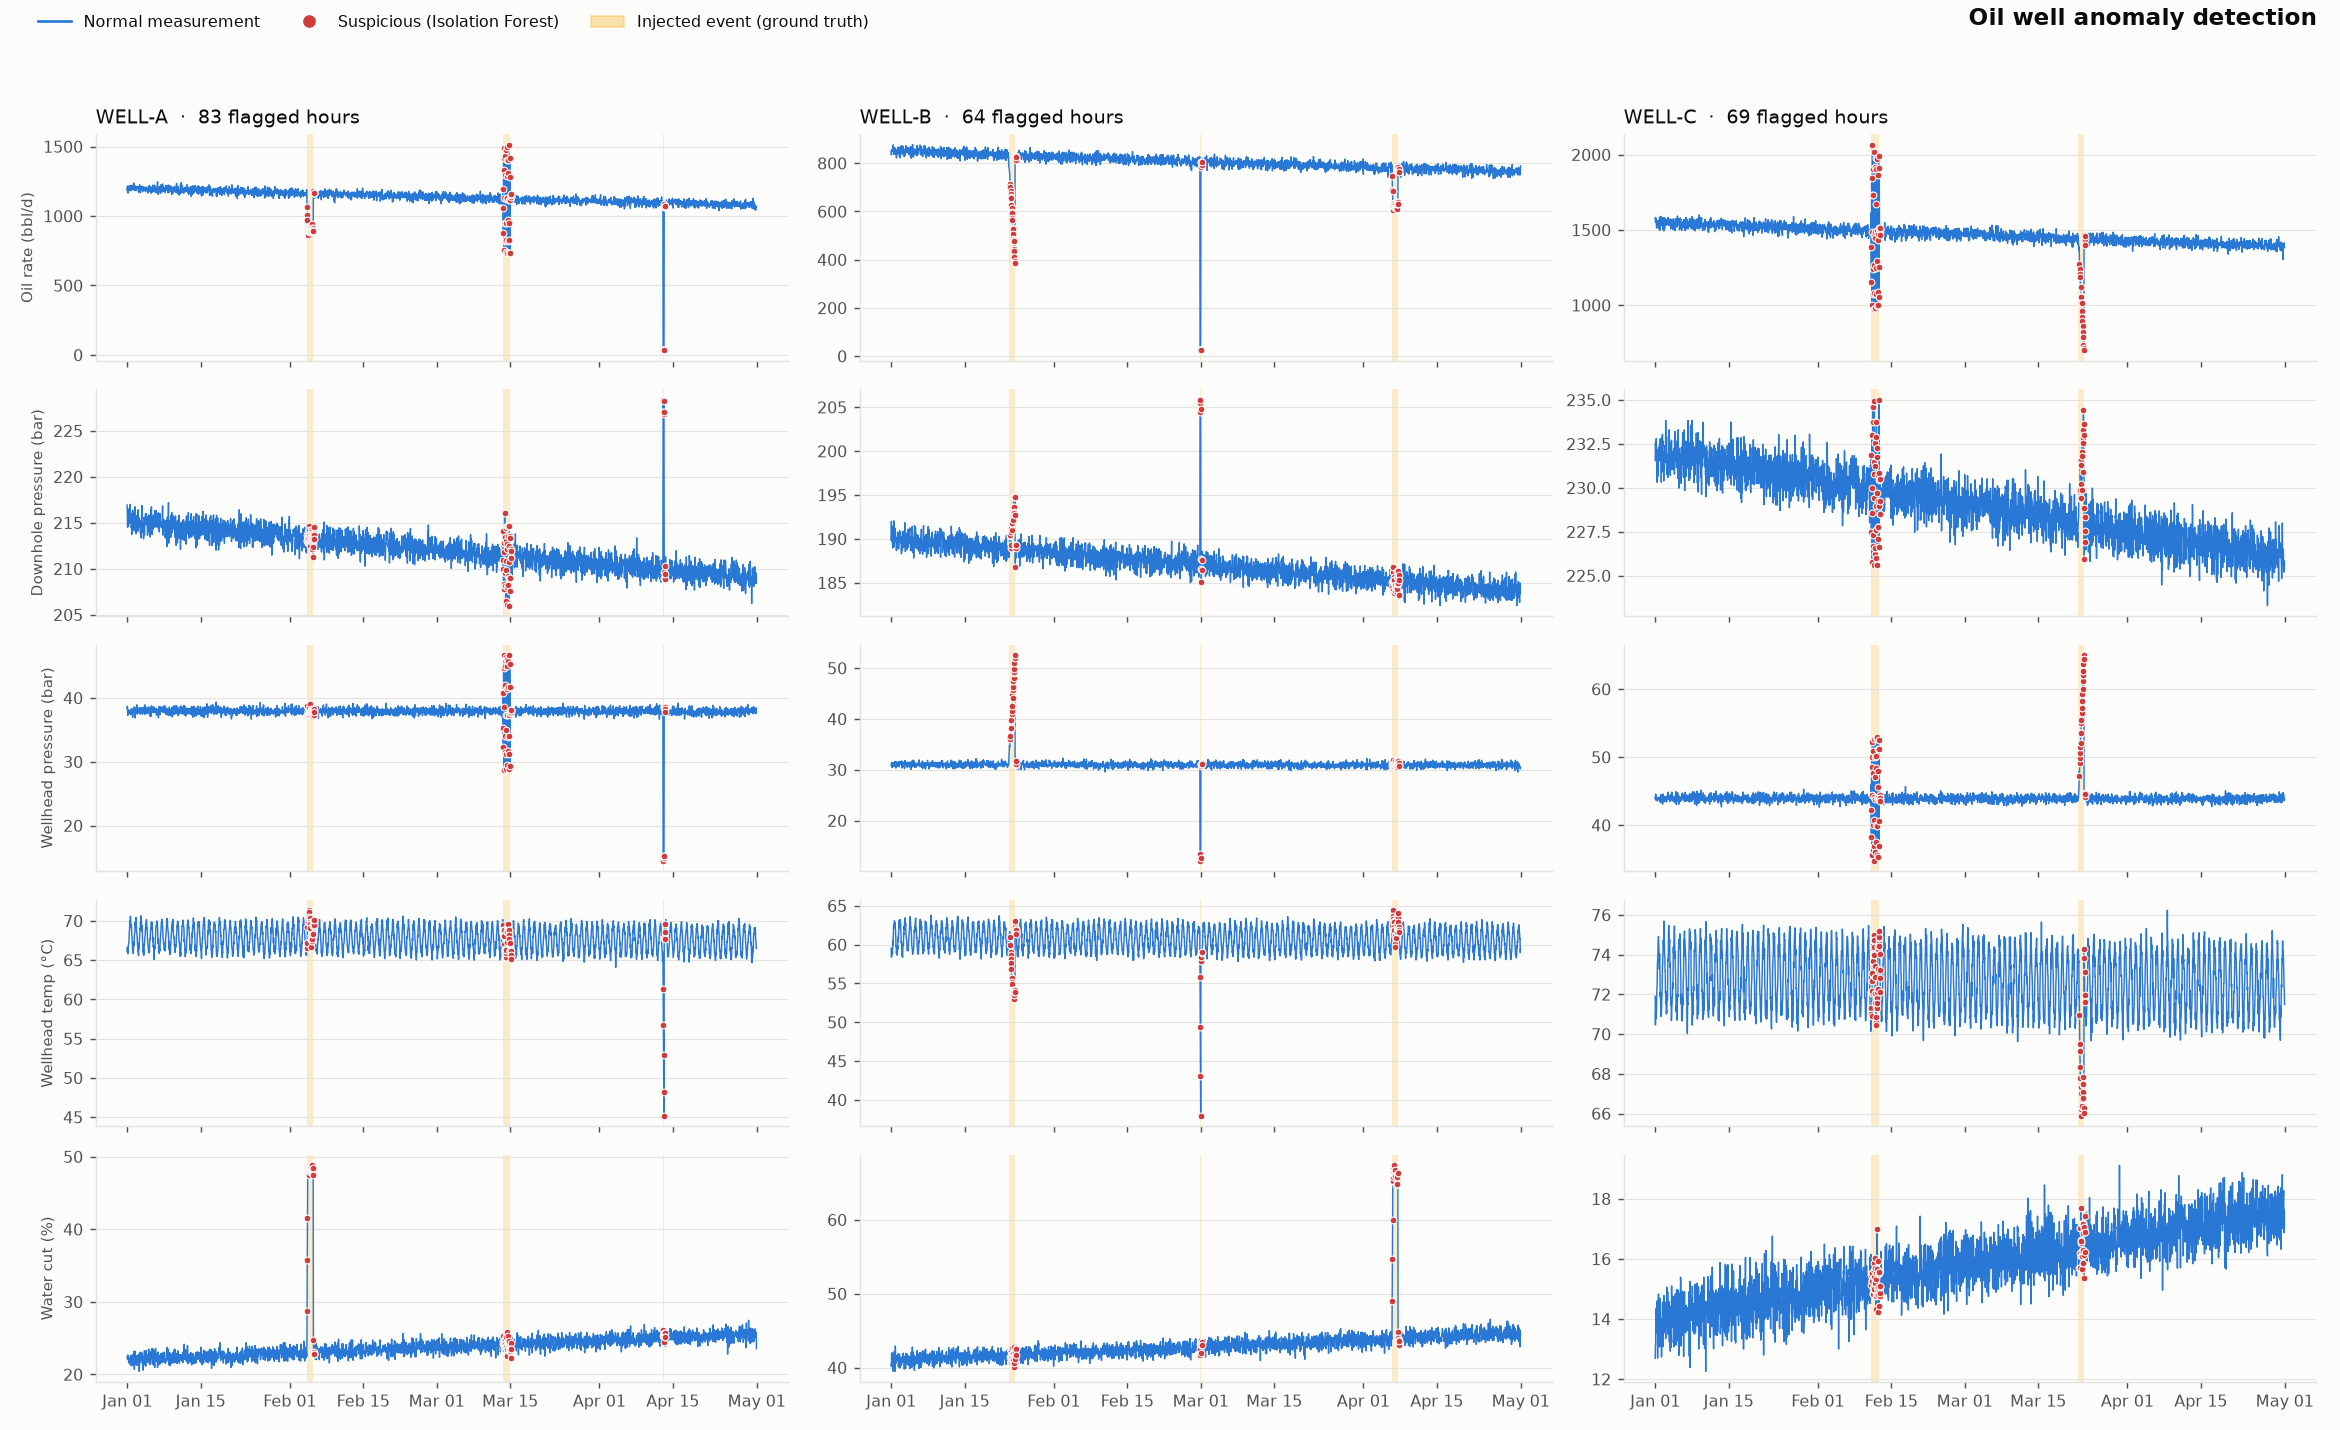

In [12]:
d.plot_results(result, d.OUTPUT_DIR / 'anomaly_plot.png')
Image(str(d.OUTPUT_DIR / 'anomaly_plot.png'))

In [13]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for flag, color, label in [(False, d.SERIES, 'normal'), (True, d.ANOMALY, 'şübhəli')]:
    ax.hist(result.loc[result['is_anomaly'] == flag, 'anomaly_score'], bins=60, color=color, alpha=0.8, label=label)
ax.set_xlabel('anomaly score (yüksək = daha qeyri-adi)'); ax.set_ylabel('saat sayı')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
plt.show()

/var/folders/n8/8xljmx8d51g7vdyqlnczfk1r0000gn/T/ipykernel_21848/2039108769.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 6. Hesabat: hansı müşahidələr araşdırılmalıdır

In [14]:
observations, episodes = d.build_report(result)
observations.to_csv(d.OUTPUT_DIR / 'suspicious_observations.csv', index=False)
episodes.to_csv(d.OUTPUT_DIR / 'anomaly_episodes.csv', index=False)
episodes

,episode_id,well_id,start,end,flagged_hours,max_score,top_reason
0,5,WELL-B,2025-02-28 21:00:00,2025-03-01 05:00:00,9,0.8038,oil_rate_bpd volatility ↑ (z=+98.7); wellhead_...
1,3,WELL-A,2025-04-13 04:00:00,2025-04-13 13:00:00,10,0.8023,oil_rate_bpd volatility ↑ (z=+90.5); wellhead_...
2,8,WELL-C,2025-02-11 04:00:00,2025-02-12 22:00:00,43,0.7293,wellhead_pressure_bar volatility ↑ (z=+54.3); ...
3,2,WELL-A,2025-03-13 15:00:00,2025-03-15 05:00:00,39,0.7252,wellhead_pressure_bar volatility ↑ (z=+51.0); ...
4,9,WELL-C,2025-03-22 21:00:00,2025-03-23 22:00:00,26,0.7187,wellhead_pressure_bar volatility ↑ (z=+60.1); ...
5,4,WELL-B,2025-01-23 16:00:00,2025-01-24 19:00:00,28,0.7173,wellhead_pressure_bar volatility ↑ (z=+61.0); ...
6,1,WELL-A,2025-02-04 07:00:00,2025-02-05 16:00:00,34,0.6869,water_cut_pct volatility ↑ (z=+52.5); water_cu...
7,6,WELL-B,2025-04-06 12:00:00,2025-04-07 02:00:00,14,0.6859,water_cut_pct volatility ↑ (z=+44.5); water_cu...
8,7,WELL-B,2025-04-07 07:00:00,2025-04-07 19:00:00,13,0.5870,water_cut_pct volatility ↑ (z=+43.3); water_cu...


In [15]:
observations.head(10)

,episode_id,priority,timestamp,well_id,oil_rate_bpd,downhole_pressure_bar,wellhead_pressure_bar,wellhead_temp_c,water_cut_pct,anomaly_score,reason
4296,5,high,2025-03-01 00:00:00,WELL-B,24.2,204.74,12.57,37.91,42.03,0.8038,oil_rate_bpd volatility ↑ (z=+98.7); wellhead_...
2455,3,high,2025-04-13 07:00:00,WELL-A,32.9,228.21,15.19,48.20,24.43,0.8023,oil_rate_bpd volatility ↑ (z=+90.5); wellhead_...
4295,5,high,2025-02-28 23:00:00,WELL-B,23.7,205.85,13.52,43.02,41.65,0.8019,oil_rate_bpd volatility ↑ (z=+105.0); wellhead...
2454,3,high,2025-04-13 06:00:00,WELL-A,32.6,226.86,14.88,52.96,25.73,0.8001,oil_rate_bpd volatility ↑ (z=+96.9); wellhead_...
4294,5,high,2025-02-28 22:00:00,WELL-B,23.9,204.50,12.07,49.34,42.54,0.7983,oil_rate_bpd volatility ↑ (z=+98.6); wellhead_...
2452,3,high,2025-04-13 04:00:00,WELL-A,33.1,228.37,15.07,61.31,25.25,0.7969,oil_rate_bpd volatility ↑ (z=+71.6); wellhead_...
2453,3,high,2025-04-13 05:00:00,WELL-A,32.4,227.09,14.47,56.74,26.08,0.7941,oil_rate_bpd volatility ↑ (z=+91.5); wellhead_...
4293,5,high,2025-02-28 21:00:00,WELL-B,24.0,205.46,12.64,55.87,43.22,0.7931,oil_rate_bpd volatility ↑ (z=+77.1); oil_rate_...
2456,3,high,2025-04-13 08:00:00,WELL-A,33.3,227.00,15.19,45.13,25.55,0.7883,oil_rate_bpd volatility ↑ (z=+71.1); wellhead_...
4297,5,high,2025-03-01 01:00:00,WELL-B,806.0,186.58,30.73,58.40,43.01,0.7826,oil_rate_bpd volatility ↑ (z=+97.2); wellhead_...


## Nəticə

- 8 hadisənin hamısı aşkarlandı, şübhəli epizodların hamısı real hadisələrə uyğundur.
- `reason` sütunu mühəndisə haradan başlamağı göstərir (məs. *water_cut_pct ↑* → su keçməsi, *wellhead_pressure_bar volatility ↑* → slugging).
- Model hadisənin **növünü** təyin etmir, yalnız normadan kənara çıxmanı göstərir.